# Part B: Staffing Model (and Part E: Sensitivity and Other Considerations)
### DADS5250 Hackathon - Boston 311 Staffing and Intake Assistant

**Author:** Larry Tsao

## Objective

Decide how many field crews each of the four departments needs in each month of 2025, including when to hire and release crews, and compare the cost and service level of different staffing plans. Part E, at the end of this notebook, tests how the recommended plan holds up when demand changes, and looks at response times by neighborhood and by who reports the request.

Departments:
- BTDT - Transportation
- ISD - Inspectional Services
- PARK - Parks and Recreation
- PWDx - Public Works

## Methodology

The 2025 demand forecast from Part A is turned into the number of crews each month needs. A staffing plan then hires, releases, or adds seasonal crews following the rules in the hackathon brief. A month-by-month backlog simulation measures each plan's cost and how many requests get closed in the month they come in.

## Deliverables

1. Crews needed per department per month.
2. A staffing plan with hires, releases, and Parks seasonal crews.
3. A cost and service comparison against holding January 2025 crew levels.
4. A recommended plan with a crew table by month.
5. A check of the simulation against real 2024 performance.
6. Visualizations of demand and crew capacity.
7. CSV exports of the crew plan and plan comparison.
8. Part E: cost and service of the recommended plan under five demand scenarios, what re-planning for 20% more or less demand would cost, and 2024 response times by neighborhood and by request source.

## Step 1: Import Libraries

This section imports the libraries used for data processing, calculations, and visualizations.

In [3]:
# ==========================================================
# Step 1: Import libraries
# ==========================================================

import math
from pathlib import Path

import lancedb
import matplotlib.pyplot as plt
import pandas as pd

## Step 2: Load Request Data and the Part A Forecast

This section loads two things from the project:

1. Part A's 2025 forecast, from `outputs/demand_forecast_2025.csv`. Run Part A first so the file exists.
2. The 2023 and 2024 requests, from the team's LanceDB `requests` table (built by `311-data-processing.ipynb`). Step 11 uses them to check the simulation against 2024.

In [4]:
# ==========================================================
# Step 2: Load request data and the Part A forecast
# ==========================================================

# Locate the project folder: the first folder, going up from here, that has data/lancedb
current_path = Path.cwd().resolve()
PROJECT_ROOT = None
for folder in [current_path] + list(current_path.parents):
    if (folder / "data" / "lancedb").exists():
        PROJECT_ROOT = folder
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Project folder not found. Open the notebook from within the project.")

OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Part A's forecast
forecast_file = OUTPUT_DIR / "demand_forecast_2025.csv"
if not forecast_file.exists():
    raise FileNotFoundError("Part A's forecast was not found. Run the Part A notebook first.")
forecast_2025 = pd.read_csv(forecast_file)

# Requests from the team database
db = lancedb.connect(PROJECT_ROOT / "data" / "lancedb")
requests = db.open_table("requests").to_pandas()
requests["year"] = requests["open_dt"].dt.year
requests["month"] = requests["open_dt"].dt.month

# Days from opening to closing (requests still open stay blank); used in Part E
requests["days_to_close"] = (requests["closed_dt"] - requests["open_dt"]).dt.total_seconds() / 86400
print("Total requests:", len(requests))

# Count requests by department, year, and month (used in Step 11)
monthly_counts = (
    requests.groupby(["department", "year", "month"])
    .size()
    .reset_index(name="request_count")
)

# Check the forecast before using it
assert len(forecast_2025) == 48, "Expected 48 forecast rows."
assert forecast_2025["department"].nunique() == 4, "Expected 4 departments."
assert (forecast_2025.groupby("department")["month"].nunique() == 12).all(), "Each department must have 12 months."
assert (forecast_2025["forecast_2025"] >= 0).all(), "Forecasts cannot be negative."

print("Forecast rows:", len(forecast_2025))
display(forecast_2025.pivot(index="month", columns="department", values="forecast_2025"))

Total requests: 558663
Forecast rows: 48


department,BTDT,ISD,PARK,PWDx
month,,,,
1,6117,1438,904,12159
2,6094,1582,772,9906
3,7623,1327,1176,11730
4,7111,1344,1455,12416
5,7704,1511,2202,13160
6,7493,1799,2774,12821
7,6594,1738,2638,13851
8,7133,1953,2417,16851
9,8015,1792,1666,15870


### Forecast Check

The forecast has 48 rows (4 departments × 12 months), loaded from Part A's output. Total 2025 requests:

- **BTDT:** 84,764
- **ISD:** 18,882
- **PARK:** 19,374
- **PWDx:** 151,327

## Step 3: Planning Assumptions from the Brief

This section stores the planning assumptions given in the hackathon brief. These numbers are assumed for the challenge, the same way a business case gives salaries.

A crew works 21 days a month, so:

Monthly capacity of one crew = requests it closes per day × 21

Other rules from the brief:
- A new crew needs **1 month** of hiring and training before it starts.
- Releasing a crew needs **1 month of notice** and costs **25%** of its annual cost.
- Parks may add **seasonal crews from April to October** at **1.3 times** the monthly cost, with no training delay and no release cost.
- Each overdue request costs **$20**. A request still open a month later costs an extra **$100**.

In [5]:
# ==========================================================
# Step 3: Planning assumptions from the brief
# ==========================================================

WORK_DAYS = 21
RELEASE_FEE = 0.25          # share of annual cost
SEASONAL_MULTIPLIER = 1.3   # Parks seasonal crews cost 30% more
OVERDUE_COST = 20           # first month a request is late
LATE_COST = 100             # extra cost when still open a month later

departments = {
    "BTDT": {"name": "Transportation", "daily_capacity": 15, "annual_cost": 110000, "starting_crews": 18},
    "ISD": {"name": "Inspectional Services", "daily_capacity": 4, "annual_cost": 140000, "starting_crews": 16},
    "PARK": {"name": "Parks and Recreation", "daily_capacity": 6, "annual_cost": 120000, "starting_crews": 10},
    "PWDx": {"name": "Public Works", "daily_capacity": 12, "annual_cost": 130000, "starting_crews": 50},
}

# Monthly capacity and monthly cost of one crew
for dept in departments:
    departments[dept]["monthly_capacity"] = departments[dept]["daily_capacity"] * WORK_DAYS
    departments[dept]["monthly_cost"] = departments[dept]["annual_cost"] / 12

display(pd.DataFrame(departments).T)

,name,daily_capacity,annual_cost,starting_crews,monthly_capacity,monthly_cost
BTDT,Transportation,15,110000,18,315,9166.666667
ISD,Inspectional Services,4,140000,16,84,11666.666667
PARK,Parks and Recreation,6,120000,10,126,10000.0
PWDx,Public Works,12,130000,50,252,10833.333333


## Step 4: Calculate Crews Needed Each Month

This section calculates how many crews each department needs to keep up with the forecast in each month:

Crews needed = forecast requests / monthly capacity of one crew, rounded up

It is rounded up, because a department cannot have part of a crew. The table also compares January's need with the starting crews from the brief.

In [6]:
# ==========================================================
# Step 4: Calculate crews needed each month
# ==========================================================

def get_crews_needed(dept, dept_demand):
    needed = []
    for requests_in_month in dept_demand:
        needed.append(math.ceil(requests_in_month / departments[dept]["monthly_capacity"]))
    return needed


demand = {}
crews_needed = {}
for dept in departments:
    dept_forecast = forecast_2025[forecast_2025["department"] == dept].sort_values("month")
    demand[dept] = dept_forecast["forecast_2025"].tolist()
    crews_needed[dept] = get_crews_needed(dept, demand[dept])

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
display(pd.DataFrame(crews_needed, index=month_labels).T)

# Compare starting crews with the average month
for dept in departments:
    average_need = sum(demand[dept]) / 12
    starting_capacity = departments[dept]["starting_crews"] * departments[dept]["monthly_capacity"]
    print(f"{dept}: starting crews can close {starting_capacity / average_need:.0%} of an average 2025 month")

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
BTDT,20,20,25,23,25,24,21,23,26,26,22,20
ISD,18,19,16,16,18,22,21,24,22,20,17,16
PARK,8,7,10,12,18,23,21,20,14,11,8,9
PWDx,49,40,47,50,53,51,55,67,63,48,41,43


BTDT: starting crews can close 80% of an average 2025 month
ISD: starting crews can close 85% of an average 2025 month
PARK: starting crews can close 78% of an average 2025 month
PWDx: starting crews can close 100% of an average 2025 month


### Crews Needed Analysis

Three departments start 2025 with fewer crews than an average month needs.

- **BTDT:** 80% of an average month. January needs 20 crews, but it only has 18.
- **ISD:** 85%. January needs 18 crews, but it only has 16.
- **PARK:** 78%. Parks actually has extra crews in winter (it needs 8 in January), but it needs 23 in June.
- **PWDx:** 100%, so it's fine on an average month. However, it needs 67 crews in August and only has 50.

Since new crews take a month to train, I have to hire ahead of the busy months.

## Step 5: Build a Staffing Plan

This section builds a month-by-month staffing plan for one department. The rules are:

1. **January** uses the starting crews from the brief.
2. **Hiring:** a crew that starts working in a month was hired the month before and spends that month in training. For example, a crew that starts in February is hired and trained in January. The plan table shows each crew in the month it starts working.
3. **Releasing:** a crew that leaves in a month was given its one month of notice the month before, and it keeps working and getting paid during that notice month. The plan table shows each release in the month the crew is gone.
4. **Only idle crews are released.** A crew is kept while requests from earlier months are still waiting for it. Otherwise it is released only if it would sit idle long enough to pay for the release. The release fee equals 3 months of pay, and a crew that is needed again later also costs 1 month of training pay to rehire, so it has to be idle for **more than 4 months in a row** (more than 3 if it is not needed again within a year). The idle count looks past December into early 2026, assuming 2026 follows the same monthly pattern as the 2025 forecast. Without that, no crew could ever be released in the fall, because too few months are left in the year. When the plan has a crew ceiling, a crew above the ceiling is never used again under that plan, so it counts as idle for the whole year.
5. **Parks** covers April to October with seasonal crews instead of permanent hires.
6. An optional **crew ceiling** (`cap`) limits how many crews the plan may use. Step 8 uses it to avoid hiring for short peaks.

The baseline plan, **Hold January**, keeps the January crews all year.

Each function takes the department's monthly demand as an input, so the same functions can be rerun with higher or lower demand for the sensitivity analysis (Part E).

In [7]:
# ==========================================================
# Step 5: Build a staffing plan
# ==========================================================

def is_parks_season(dept, month_index):
    # month_index runs from 0 (January) to 11 (December)
    month_number = month_index + 1
    return dept == "PARK" and 4 <= month_number <= 10


def idle_months(target, start, crews):
    # Count how many months in a row, starting at `start`, the department needs fewer than `crews` crews.
    # After December it keeps counting into 2026, assuming 2026 follows the same monthly pattern as 2025.
    count = 0
    for step in range(12):
        m = (start + step) % 12
        if target[m] >= crews:
            break
        count = count + 1
    return count


def make_plan(dept, dept_demand, cap=None):
    needed = get_crews_needed(dept, dept_demand)

    # Crews the plan aims for each month, limited by the ceiling if there is one
    target = []
    for n in needed:
        if cap is not None and n > cap:
            target.append(cap)
        else:
            target.append(n)

    # January is fixed at the starting crews
    permanent = [departments[dept]["starting_crews"]]
    hires = [0]
    releases = [0]

    # Requests still waiting at the end of January
    capacity = departments[dept]["monthly_capacity"]
    waiting = max(0, dept_demand[0] - permanent[0] * capacity)

    # February (index 1) to December (index 11)
    for m in range(1, 12):
        crews = permanent[-1]
        hired = 0
        released = 0

        # Hire up to the month's need (Parks uses seasonal crews in season instead)
        if target[m] > crews and not is_parks_season(dept, m):
            hired = target[m] - crews
            crews = target[m]

        # Crews needed to close this month's requests plus the ones still waiting
        needed_with_waiting = math.ceil((waiting + dept_demand[m]) / capacity)

        # Release only idle crews, and only if the idle stretch pays for the release
        while crews > max(target[m], needed_with_waiting):
            idle = idle_months(target, m, crews)
            if idle == 12:
                break_even = 3   # never needed again: release fee only
            else:
                break_even = 4   # needed again later: release fee + 1 month of training pay
            if idle <= break_even:
                break
            crews = crews - 1
            released = released + 1

        permanent.append(crews)
        hires.append(hired)
        releases.append(released)

        # Requests still waiting at the end of this month (Parks seasonal crews count in season)
        if is_parks_season(dept, m):
            working_crews = crews + max(0, target[m] - crews)
        else:
            working_crews = crews
        waiting = max(0, waiting + dept_demand[m] - working_crews * capacity)

    # Parks seasonal crews fill any gap from April to October
    seasonal = []
    for m in range(12):
        if is_parks_season(dept, m):
            seasonal.append(max(0, target[m] - permanent[m]))
        else:
            seasonal.append(0)

    return pd.DataFrame({
        "month": month_labels,
        "demand": dept_demand,
        "crews_needed": needed,
        "permanent": permanent,
        "hires": hires,
        "releases": releases,
        "seasonal": seasonal,
    })


def hold_january_plan(dept, dept_demand):
    starting = departments[dept]["starting_crews"]
    return pd.DataFrame({
        "month": month_labels,
        "demand": dept_demand,
        "crews_needed": get_crews_needed(dept, dept_demand),
        "permanent": [starting] * 12,
        "hires": [0] * 12,
        "releases": [0] * 12,
        "seasonal": [0] * 12,
    })


# Example: Transportation under the full-coverage rule
display(make_plan("BTDT", demand["BTDT"]))

,month,demand,crews_needed,permanent,hires,releases,seasonal
0,Jan,6117,20,18,0,0,0
1,Feb,6094,20,20,2,0,0
2,Mar,7623,25,25,5,0,0
3,Apr,7111,23,25,0,0,0
4,May,7704,25,25,0,0,0
5,Jun,7493,24,25,0,0,0
6,Jul,6594,21,25,0,0,0
7,Aug,7133,23,25,0,0,0
8,Sep,8015,26,26,1,0,0
9,Oct,7945,26,26,0,0,0


## Step 6: Simulate the Backlog and Cost

This section plays out a plan month by month. Each month:

1. Crews close requests up to their capacity, **oldest first**.
2. A new request still open at the end of its first month is **overdue** and costs **$20**.
3. A request still open at the end of the next month costs an extra **$100**. The brief charges this at 30 days past the request's target date; the team plan uses the month boundary instead.
4. A request is counted as **closed same month** if it is closed in the month it was opened. This is the model's stand-in for "on time" (Step 11 explains how it compares with the city's real target dates).

**Training pay:** the brief does not say whether the month of hiring and training is paid. To me it makes more sense to have the training month paid, so every new permanent crew costs one extra month of pay for its training month. Parks seasonal crews have no training delay, so they have no training cost.

Total cost = crew pay + seasonal crew pay (at 1.3 times) + training pay + release fees + overdue costs

The 2025 simulation starts with no backlog, as the brief allows. Costs are the costs incurred during 2025, so the backlog still open in December is reported separately.

In [8]:
# ==========================================================
# Step 6: Simulate the backlog and cost
# ==========================================================

def simulate(dept, plan):
    info = departments[dept]
    plan = plan.reset_index(drop=True)  # rows numbered 0-11, even if the plan was filtered from a bigger table
    carried_once = 0    # requests left over from last month
    carried_twice = 0   # requests left over for two months or more
    closed_same_month = 0
    overdue_cost = 0

    for m in range(12):
        capacity = (plan["permanent"][m] + plan["seasonal"][m]) * info["monthly_capacity"]
        new_requests = plan["demand"][m]

        # Close the oldest requests first
        close_twice = min(carried_twice, capacity)
        capacity = capacity - close_twice
        close_once = min(carried_once, capacity)
        capacity = capacity - close_once
        close_new = min(new_requests, capacity)
        closed_same_month = closed_same_month + close_new

        # Whatever is left becomes next month's backlog
        new_left = new_requests - close_new
        once_left = carried_once - close_once
        twice_left = carried_twice - close_twice
        overdue_cost = overdue_cost + new_left * OVERDUE_COST + once_left * LATE_COST
        carried_twice = twice_left + once_left
        carried_once = new_left

    crew_cost = (plan["permanent"] * info["monthly_cost"]).sum()
    seasonal_cost = (plan["seasonal"] * info["monthly_cost"] * SEASONAL_MULTIPLIER).sum()
    training_cost = plan["hires"].sum() * info["monthly_cost"]
    release_cost = plan["releases"].sum() * info["annual_cost"] * RELEASE_FEE
    total_cost = crew_cost + seasonal_cost + training_cost + release_cost + overdue_cost

    return {
        "department": dept,
        "crew_cost": crew_cost + seasonal_cost,
        "training_cost": training_cost,
        "release_cost": release_cost,
        "overdue_cost": overdue_cost,
        "total_cost": total_cost,
        "same_month_rate": closed_same_month / plan["demand"].sum(),
        "backlog_in_december": carried_once + carried_twice,
        "requests": plan["demand"].sum(),
        "closed_same_month": closed_same_month,
    }


# Example: Transportation under the full-coverage rule
simulate("BTDT", make_plan("BTDT", demand["BTDT"]))

{'department': 'BTDT',
 'crew_cost': np.float64(2658333.333333333),
 'training_cost': np.float64(73333.33333333333),
 'release_cost': np.float64(27500.0),
 'overdue_cost': np.int64(13760),
 'total_cost': np.float64(2772926.6666666665),
 'same_month_rate': np.float64(0.9918833467037893),
 'backlog_in_december': np.int64(0),
 'requests': np.int64(84764),
 'closed_same_month': np.int64(84076)}

## Step 7: Compare Full Coverage with Holding January

This section compares two plans for every department:

- **Hold January:** keep the January 2025 crews all year.
- **Full coverage:** the team plan's rule from Step 5, with no crew ceiling.

In [9]:
# ==========================================================
# Step 7: Compare full coverage with holding January
# ==========================================================

results = []
for dept in departments:
    result = simulate(dept, hold_january_plan(dept, demand[dept]))
    result["plan"] = "Hold January"
    results.append(result)

    result = simulate(dept, make_plan(dept, demand[dept]))
    result["plan"] = "Full coverage"
    results.append(result)

comparison = pd.DataFrame(results)
display(comparison[["plan", "department", "total_cost", "same_month_rate", "backlog_in_december"]].round(3))

,plan,department,total_cost,same_month_rate,backlog_in_december
0,Hold January,BTDT,6598620.000,0.235,16724
1,Full coverage,BTDT,2772926.667,0.992,0
2,Hold January,ISD,2918920.000,0.368,2754
3,Full coverage,ISD,3071813.333,0.991,0
4,Hold January,PARK,2520380.000,0.274,5182
5,Full coverage,PARK,1837000.000,1.000,0
6,Hold January,PWDx,7272900.000,0.745,4316
7,Full coverage,PWDx,7680833.333,1.000,0


### Full Coverage vs Hold January Analysis

Full coverage closes over 99% of requests in the same month for every department. Holding January only closes between 23.5% (BTDT) and 74.5% (PWDx).

- **BTDT:** $6.60M down to $2.77M, since holding January lets the backlog keep growing.
- **PARK:** $2.52M down to $1.84M.
- **ISD:** $2.92M up to $3.07M.
- **PWDx:** $7.27M up to $7.68M.

Full coverage costs more for ISD and PWDx because it hires crews for short busy stretches and pays to train and release them. For example, it hires 12 Public Works crews for August and releases all of them by October. Step 8 looks for a plan that avoids this.

## Step 8: Find the Recommended Crew Ceiling

Full coverage hires for every peak, even one that lasts a single month. This section tries one crew ceiling at a time for each department, from its highest monthly need down to its lowest, and keeps:

- **Recommended:** the cheapest ceiling that still closes at least **95%** of requests in the same month. The 95% floor is our team's choice, not a number from the brief.
- **Cheapest ceiling tested:** the ceiling with the lowest total cost, whatever the service level.

This only tests one ceiling per department, so it is not a search over every possible month-by-month schedule.

In [10]:
# ==========================================================
# Step 8: Find the recommended crew ceiling
# ==========================================================

MIN_SAME_MONTH_RATE = 0.95

recommended_cap = {}
cheapest_cap = {}
search_results = {}

for dept in departments:
    options = []
    needed = get_crews_needed(dept, demand[dept])
    highest_need = max(needed)
    lowest_need = min(needed)
    for cap in range(highest_need, lowest_need - 1, -1):
        result = simulate(dept, make_plan(dept, demand[dept], cap))
        options.append({"cap": cap, "total_cost": result["total_cost"], "same_month_rate": result["same_month_rate"]})
    options = pd.DataFrame(options)
    search_results[dept] = options

    # Cheapest ceiling of all
    by_cost = options.sort_values("total_cost")
    cheapest_cap[dept] = by_cost["cap"].iloc[0]

    # Cheapest ceiling that still meets the 95% floor (if none does, use no ceiling)
    good_enough = by_cost[by_cost["same_month_rate"] >= MIN_SAME_MONTH_RATE]
    if len(good_enough) > 0:
        recommended_cap[dept] = good_enough["cap"].iloc[0]
    else:
        recommended_cap[dept] = highest_need

    print(f"{dept}: recommended ceiling {recommended_cap[dept]} crews, cheapest ceiling tested {cheapest_cap[dept]} crews")

# Show the search for Inspectional Services as an example
display(search_results["ISD"].round(3))

BTDT: recommended ceiling 24 crews, cheapest ceiling tested 24 crews
ISD: recommended ceiling 21 crews, cheapest ceiling tested 18 crews
PARK: recommended ceiling 21 crews, cheapest ceiling tested 19 crews
PWDx: recommended ceiling 58 crews, cheapest ceiling tested 52 crews


,cap,total_cost,same_month_rate
0,24,3071813.333,0.991
1,23,3013900.000,0.990
2,22,2969893.333,0.983
3,21,2885040.000,0.960
4,20,2798853.333,0.879
5,19,2750960.000,0.759
6,18,2659680.000,0.630
7,17,2699160.000,0.496
8,16,2918920.000,0.368


## Step 9: Compare All Four Plans

This section compares the four plans for each department and in total.

In [11]:
# ==========================================================
# Step 9: Compare all four plans
# ==========================================================

results = []
for dept in departments:
    plans_to_compare = {
        "Hold January": hold_january_plan(dept, demand[dept]),
        "Full coverage": make_plan(dept, demand[dept]),
        "Recommended (95% same month)": make_plan(dept, demand[dept], recommended_cap[dept]),
        "Cheapest ceiling tested": make_plan(dept, demand[dept], cheapest_cap[dept]),
    }
    for plan_name in plans_to_compare:
        result = simulate(dept, plans_to_compare[plan_name])
        result["plan"] = plan_name
        results.append(result)

comparison = pd.DataFrame(results)

# Totals across all four departments
money_columns = ["crew_cost", "training_cost", "release_cost", "overdue_cost", "total_cost"]
totals = comparison.groupby("plan", sort=False)[money_columns + ["requests", "closed_same_month", "backlog_in_december"]].sum()
totals["same_month_rate"] = totals["closed_same_month"] / totals["requests"]

summary = totals[money_columns] / 1_000_000
summary = summary.round(2)
summary["same_month_rate"] = totals["same_month_rate"].round(3)
summary["backlog_in_december"] = totals["backlog_in_december"]

print("Totals for all departments (costs in $ millions):")
display(summary)

print("Share of requests closed in the same month, by department:")
display(comparison.pivot(index="department", columns="plan", values="same_month_rate").round(3))

print("Total cost by department ($ millions):")
cost_by_department = comparison.pivot(index="department", columns="plan", values="total_cost") / 1_000_000
display(cost_by_department.round(2))

Totals for all departments (costs in $ millions):


,crew_cost,training_cost,release_cost,overdue_cost,total_cost,same_month_rate,backlog_in_december
plan,,,,,,,
Hold January,11.92,0.00,0.00,7.39,19.31,0.528,28976
Full coverage,14.21,0.35,0.79,0.02,15.36,0.997,0
Recommended (95% same month),13.96,0.20,0.36,0.20,14.72,0.963,0
Cheapest ceiling tested,13.46,0.10,0.00,0.69,14.26,0.874,1620


Share of requests closed in the same month, by department:


plan,Cheapest ceiling tested,Full coverage,Hold January,Recommended (95% same month)
department,,,,
BTDT,0.970,0.992,0.235,0.970
ISD,0.630,0.991,0.368,0.960
PARK,0.850,1.000,0.274,0.986
PWDx,0.854,1.000,0.745,0.957


Total cost by department ($ millions):


plan,Cheapest ceiling tested,Full coverage,Hold January,Recommended (95% same month)
department,,,,
BTDT,2.66,2.77,6.60,2.66
ISD,2.66,3.07,2.92,2.89
PARK,1.80,1.84,2.52,1.82
PWDx,7.14,7.68,7.27,7.37


### Plan Comparison Analysis

I think the recommended plan is the best balance between cost and service.

- **Hold January:** $19.31M, with 52.8% of requests closed in the same month
- **Full coverage:** $15.36M, 99.7%
- **Recommended:** $14.72M, 96.3%
- **Cheapest ceiling tested:** $14.26M, 87.4%

The recommended plan saves $4.59M compared to holding January and $0.64M compared to full coverage, since it doesn't hire crews for short peaks. The cheapest ceiling saves another $0.47M, but Inspectional Services drops to 63% and it leaves 1,620 requests open in December, so I don't think it's worth it.

These are 2025 costs only. The release fees in the fall count in 2025, but most of what the releases save is idle pay in early 2026, which isn't in these totals.

## Step 10: Recommended Crew Table

This section shows the recommended plan's crews for each department and month.

- `(+n)` marks new crews that start working that month (hired and trained the month before).
- `(-n)` marks crews that are gone that month (given notice the month before).
- `+ns` marks Parks seasonal crews.

In [12]:
# ==========================================================
# Step 10: Recommended crew table
# ==========================================================

def crew_labels(plan):
    labels = []
    for m in range(12):
        text = str(plan["permanent"][m])
        if plan["hires"][m] > 0:
            text = text + f" (+{plan['hires'][m]})"
        if plan["releases"][m] > 0:
            text = text + f" (-{plan['releases'][m]})"
        if plan["seasonal"][m] > 0:
            text = text + f" +{plan['seasonal'][m]}s"
        labels.append(text)
    return labels


recommended_table = {}
full_coverage_table = {}
for dept in departments:
    recommended_table[dept] = crew_labels(make_plan(dept, demand[dept], recommended_cap[dept]))
    full_coverage_table[dept] = crew_labels(make_plan(dept, demand[dept]))

print("Recommended plan:")
display(pd.DataFrame(recommended_table, index=month_labels).T)

print("Full coverage, for comparison:")
display(pd.DataFrame(full_coverage_table, index=month_labels).T)

Recommended plan:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
BTDT,18,20 (+2),24 (+4),24,24,24,24,24,24,24,24,24
ISD,16,19 (+3),19,19,19,21 (+2),21,21,21,21,19 (-2),19
PARK,10,10,10,10 +2s,10 +8s,10 +11s,10 +11s,10 +10s,10 +4s,10 +1s,10,10
PWDx,50,50,50,50,53 (+3),53,55 (+2),58 (+3),58,58,49 (-9),49


Full coverage, for comparison:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
BTDT,18,20 (+2),25 (+5),25,25,25,25,25,26 (+1),26,25 (-1),25
ISD,16,19 (+3),19,19,19,22 (+3),22,24 (+2),22 (-2),20 (-2),19 (-1),19
PARK,10,10,10,10 +2s,10 +8s,10 +13s,10 +11s,10 +10s,10 +4s,10 +1s,10,10
PWDx,50,50,50,50,53 (+3),53,55 (+2),67 (+12),63 (-4),49 (-14),49,49


### Recommended Crew Plan Analysis

- **BTDT:** adds 2 crews in February and 4 in March to get to 24, and keeps them all year.
- **ISD:** adds 3 crews in February and 2 in June to get to 21, then releases 2 in November.
- **PARK:** keeps its 10 permanent crews and adds seasonal crews from April to October (up to 11 in June and July).
- **PWDx:** stays at 50 crews through April, builds up to 58 by August, then releases 9 in November. It keeps them through October to close the requests left over from the summer, and the 49 crews left can close the rest in November.

Compared to full coverage, the recommended plan doesn't chase single-month peaks. For example, Public Works stops at 58 crews in August instead of 67.

## Step 11: Check the Simulation Against 2024

This section runs the same simulation on **2024 actual counts** at January 2025 crew levels and compares its same-month closure rate with the city's real 2024 on-time rate. It also counts the 2024 requests that have no target date, and how the city scored them.

In [13]:
# ==========================================================
# Step 11: Check the simulation against 2024
# ==========================================================

check = []
for dept in departments:
    actual_2024 = monthly_counts[(monthly_counts["department"] == dept) & (monthly_counts["year"] == 2024)]
    demand_2024 = actual_2024.sort_values("month")["request_count"].tolist()

    dept_2024 = requests[(requests["department"] == dept) & (requests["year"] == 2024)]
    check.append({
        "department": dept,
        "simulated_same_month": simulate(dept, hold_january_plan(dept, demand_2024))["same_month_rate"],
        "real_on_time_2024": (dept_2024["on_time"] == "ONTIME").mean(),
    })

check = pd.DataFrame(check)
check["gap"] = check["real_on_time_2024"] - check["simulated_same_month"]
display(check.round(3))

# Requests with no target date, and how the city scored them
requests_2024 = requests[requests["year"] == 2024]
no_target = requests_2024[requests_2024["sla_target_dt"].isna()]
print(f"2024 requests with no target date: {len(no_target):,} of {len(requests_2024):,} ({len(no_target) / len(requests_2024):.1%})")
print("By department:")
display(no_target["department"].value_counts())
print("How the city scored them:")
display(no_target["on_time"].value_counts())

,department,simulated_same_month,real_on_time_2024,gap
0,BTDT,0.291,0.499,0.208
1,ISD,0.421,0.724,0.303
2,PARK,0.287,0.932,0.644
3,PWDx,0.635,0.897,0.262


2024 requests with no target date: 31,421 of 276,417 (11.4%)
By department:


department
PWDx    29339
BTDT     1600
PARK      415
ISD        67
Name: count, dtype: int64

How the city scored them:


on_time
ONTIME    31421
Name: count, dtype: int64

### Simulation Check Analysis

The simulation's numbers are a lot lower than the city's real 2024 on-time rates, especially for **PARK** (29% simulated vs 93% real). I think there are three reasons:

- My model counts a request as late once it rolls past the month it was opened. The city's real target dates are often longer, and a lot of Parks requests get 365 days.
- 31,421 of the 276,417 requests in the four departments in 2024 (11.4%) have no target date (the brief's 16% is for the whole city), mostly in Public Works (29,339), and the city marked every one of them on time.
- The crew numbers are the brief's planning assumptions, not the city's real staffing.

So the rates in this notebook are good for comparing plans with each other, but not for predicting the city's real on-time numbers.

## Step 12: Visualize Demand and Crew Capacity

This section creates a chart for each department comparing the 2025 forecast with how many requests each plan's crews can close per month.

Each chart displays:
- **Forecast:** predicted monthly requests from Part A (bars).
- **Recommended:** monthly capacity under the recommended plan.
- **Full coverage:** monthly capacity under the team plan's rule.
- **Hold January:** monthly capacity at January 2025 crew levels.

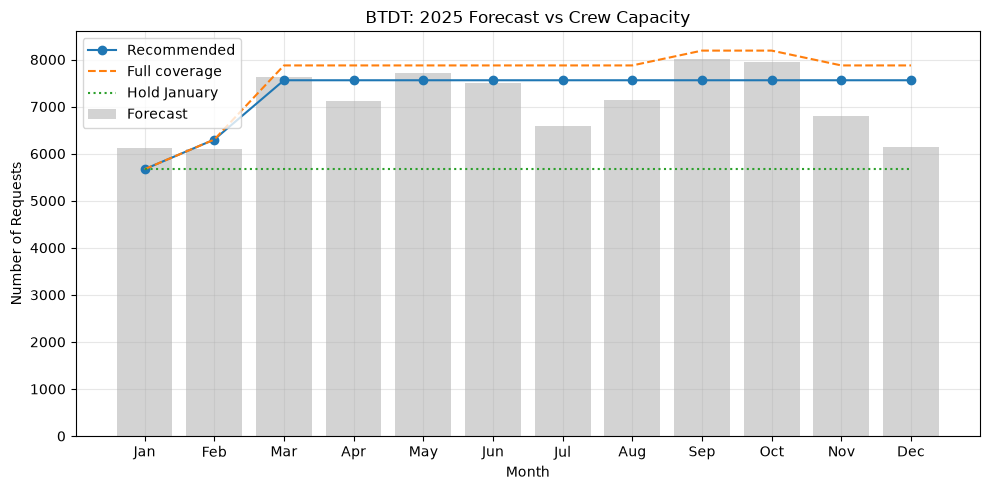

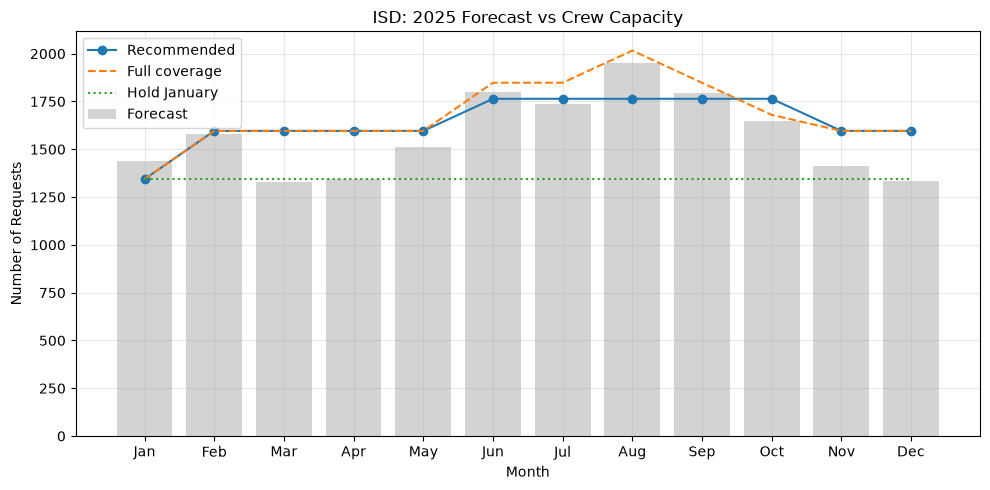

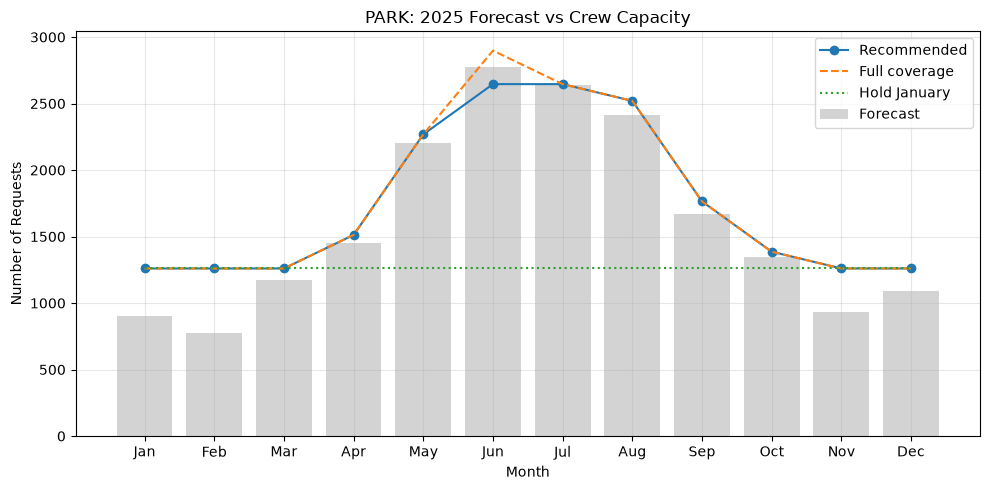

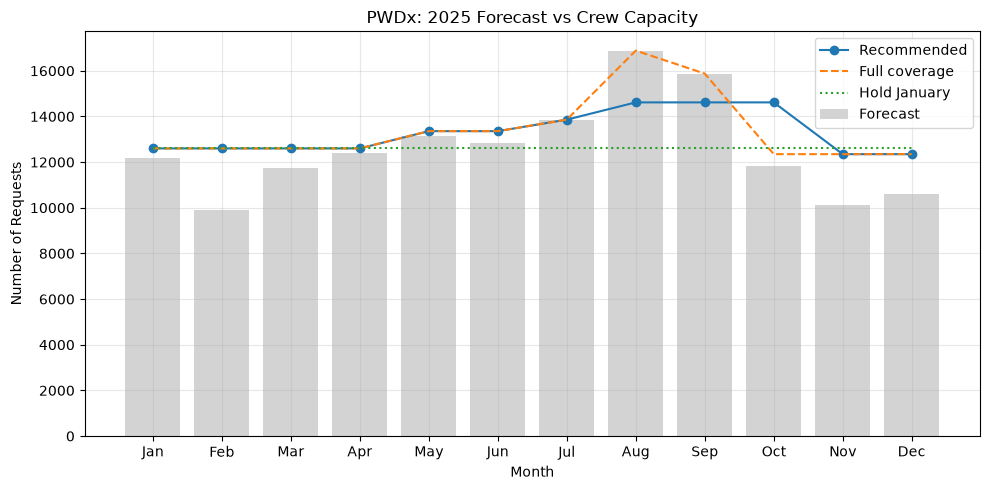

In [14]:
# ==========================================================
# Step 12: Visualize demand and crew capacity
# ==========================================================

for dept in departments:
    capacity_per_crew = departments[dept]["monthly_capacity"]
    recommended = make_plan(dept, demand[dept], recommended_cap[dept])
    full = make_plan(dept, demand[dept])
    hold = hold_january_plan(dept, demand[dept])

    plt.figure(figsize=(10, 5))
    plt.bar(month_labels, demand[dept], color="lightgray", label="Forecast")
    plt.plot(month_labels, (recommended["permanent"] + recommended["seasonal"]) * capacity_per_crew, marker="o", label="Recommended")
    plt.plot(month_labels, (full["permanent"] + full["seasonal"]) * capacity_per_crew, linestyle="--", label="Full coverage")
    plt.plot(month_labels, hold["permanent"] * capacity_per_crew, linestyle=":", label="Hold January")

    plt.title(f"{dept}: 2025 Forecast vs Crew Capacity")
    plt.xlabel("Month")
    plt.ylabel("Number of Requests")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## Step 13: Export the Staffing Plan

This section saves the recommended crew plan and the plan comparison as CSV files in the `outputs` folder, the same folder Part A uses, so the integration notebook and the sensitivity analysis can load them.

In [15]:
# ==========================================================
# Step 13: Export the staffing plan
# ==========================================================

OUTPUT_DIR.mkdir(exist_ok=True)

# One row per department and month for the recommended plan
plan_rows = []
for dept in departments:
    plan = make_plan(dept, demand[dept], recommended_cap[dept])
    plan.insert(0, "department", dept)
    plan_rows.append(plan)
staffing_plan = pd.concat(plan_rows)

assert len(staffing_plan) == 48, "Expected 48 plan rows."

plan_file = OUTPUT_DIR / "staffing_plan_2025.csv"
comparison_file = OUTPUT_DIR / "staffing_plan_comparison_2025.csv"
staffing_plan.to_csv(plan_file, index=False)
comparison.to_csv(comparison_file, index=False)

print(f"CSV saved to: {plan_file.relative_to(PROJECT_ROOT)}")
print(f"CSV saved to: {comparison_file.relative_to(PROJECT_ROOT)}")

CSV saved to: outputs/staffing_plan_2025.csv
CSV saved to: outputs/staffing_plan_comparison_2025.csv


## Conclusion

- Holding January crew levels all year is the most expensive plan ($19.31M), since the backlog builds up and about half of requests run late.
- The recommended plan hires ahead of demand, uses seasonal crews for the Parks summer peak, and releases crews in the fall once demand drops. It costs **$14.72M** and closes **96.3%** of requests in the same month.
- Full coverage gets to 99.7%, but it costs $0.64M more, mostly from crews hired for short peaks.

Part E below tests how this plan holds up when demand is higher or lower than the forecast.

# Part E: Sensitivity and Other Considerations

Part E uses the functions and the recommended plan from Part B above, so run Part B first.

## Step 14: Test the Recommended Plan Under Five Demand Scenarios

This section keeps the recommended plan exactly as it is (same crews, hires, releases, and seasonal crews) and changes only the number of requests:

1. **Forecast:** Part A's forecast, for comparison.
2. **Demand 20% higher:** every month 20% above the forecast.
3. **Demand 20% lower:** every month 20% below the forecast.
4. **February snowstorm:** Public Works gets 50% more requests in February.
5. **July heat wave:** Parks and Inspectional Services get 50% more requests in July.

The brief does not say how big a snowstorm or heat wave spike is. The 50% spikes are our team's assumption.

In [16]:
# ==========================================================
# Step 14: Test the recommended plan under five demand scenarios
# ==========================================================

scenario_names = ["Forecast", "Demand 20% higher", "Demand 20% lower", "February snowstorm", "July heat wave"]


def scenario_demand(dept, scenario):
    # Returns the department's 12 monthly request counts under one scenario
    new_demand = []
    for m in range(12):
        requests_in_month = demand[dept][m]
        if scenario == "Demand 20% higher":
            requests_in_month = requests_in_month * 1.2
        elif scenario == "Demand 20% lower":
            requests_in_month = requests_in_month * 0.8
        elif scenario == "February snowstorm" and dept == "PWDx" and m == 1:
            requests_in_month = requests_in_month * 1.5
        elif scenario == "July heat wave" and dept in ["PARK", "ISD"] and m == 6:
            requests_in_month = requests_in_month * 1.5
        new_demand.append(round(requests_in_month))
    return new_demand


scenario_results = []
for scenario in scenario_names:
    for dept in departments:
        # Same recommended plan every time; only the requests change
        plan = make_plan(dept, demand[dept], recommended_cap[dept])
        plan["demand"] = scenario_demand(dept, scenario)
        result = simulate(dept, plan)
        result["scenario"] = scenario
        scenario_results.append(result)

scenario_results = pd.DataFrame(scenario_results)

# Totals across all four departments
scenario_totals = scenario_results.groupby("scenario", sort=False)[["total_cost", "overdue_cost", "requests", "closed_same_month", "backlog_in_december"]].sum()
scenario_totals["same_month_rate"] = scenario_totals["closed_same_month"] / scenario_totals["requests"]

scenario_summary = pd.DataFrame({
    "requests": scenario_totals["requests"],
    "total_cost ($M)": (scenario_totals["total_cost"] / 1_000_000).round(2),
    "overdue_cost ($M)": (scenario_totals["overdue_cost"] / 1_000_000).round(2),
    "same_month_rate": scenario_totals["same_month_rate"].round(3),
    "backlog_in_december": scenario_totals["backlog_in_december"],
})
print("Recommended plan under each scenario, all departments:")
display(scenario_summary)

print("Share of requests closed in the same month, by department:")
display(scenario_results.pivot(index="department", columns="scenario", values="same_month_rate")[scenario_names].round(3))

Recommended plan under each scenario, all departments:


,requests,total_cost ($M),overdue_cost ($M),same_month_rate,backlog_in_december
scenario,,,,,
Forecast,274347,14.72,0.20,0.963,0
Demand 20% higher,329217,24.98,10.46,0.314,41858
Demand 20% lower,219477,14.52,0.00,1.000,0
February snowstorm,279300,14.89,0.36,0.935,0
July heat wave,276535,14.95,0.43,0.922,1239


Share of requests closed in the same month, by department:


scenario,Forecast,Demand 20% higher,Demand 20% lower,February snowstorm,July heat wave
department,,,,,
BTDT,0.970,0.211,1.0,0.970,0.970
ISD,0.960,0.297,1.0,0.960,0.718
PARK,0.986,0.437,1.0,0.986,0.666
PWDx,0.957,0.359,1.0,0.906,0.957


### Sensitivity Analysis

The plan only stays above our 95% floor when demand is lower than the forecast.

- **Demand 20% higher:** total cost goes from $14.72M to $24.98M, and only 31.4% of requests get closed in the same month. 41,858 requests are still open in December. Overdue costs alone go up to $10.46M, because there aren't enough crews and the backlog keeps building.
- **Demand 20% lower:** every request gets closed in the same month, but the cost only drops to $14.52M, since the crews still get paid when there's less work.
- **February snowstorm:** Public Works drops from 95.7% to 90.6% closed in the same month (93.5% for all departments, under our 95% floor) and costs $0.16M more. It does catch up, so nothing is left open in December.
- **July heat wave:** Parks drops to 67% and ISD to 72% (92.2% overall), and it costs $0.23M more. 1,239 requests (702 Parks, 537 ISD) are still open in December, so those two departments don't catch up by the end of the year.

So a one-month spike doesn't cost much more, but service drops below our 95% floor, especially for Parks and ISD after a heat wave. If demand ends up a lot higher than the forecast for the whole year, the city would need more crews.

## Step 15: What Re-planning for 20% More or Less Demand Would Take

Step 14 shows what happens if demand changes and the plan does not. This section shows the other side: if the city knew ahead of time that demand would be 20% higher or lower, what would the recommended plan look like? It reruns the Step 8 rule (the cheapest crew ceiling that still closes at least 95% of requests in the same month) on the changed demand.

In [17]:
# ==========================================================
# Step 15: What re-planning for 20% more or less demand would take
# ==========================================================

def find_recommended_cap(dept, dept_demand):
    # Same rule as Step 8: the cheapest ceiling that still closes at least 95% in the same month
    needed = get_crews_needed(dept, dept_demand)
    best_cap = max(needed)
    best_cost = None
    for cap in range(max(needed), min(needed) - 1, -1):
        result = simulate(dept, make_plan(dept, dept_demand, cap))
        if result["same_month_rate"] >= MIN_SAME_MONTH_RATE:
            if best_cost is None or result["total_cost"] < best_cost:
                best_cap = cap
                best_cost = result["total_cost"]
    if best_cost is None:
        print(f"{dept}: no ceiling reaches {MIN_SAME_MONTH_RATE:.0%}, so the highest need ({best_cap} crews) is used")
    return best_cap


replan_rows = []
for scenario in ["Demand 20% higher", "Demand 20% lower"]:
    for dept in departments:
        new_demand = scenario_demand(dept, scenario)

        # Plan kept the same (as in Step 14)
        kept_plan = make_plan(dept, demand[dept], recommended_cap[dept])
        kept_plan["demand"] = new_demand
        kept = simulate(dept, kept_plan)

        # Plan redone for the new demand
        new_cap = find_recommended_cap(dept, new_demand)
        redone = simulate(dept, make_plan(dept, new_demand, new_cap))

        replan_rows.append({
            "scenario": scenario,
            "department": dept,
            "ceiling_kept": recommended_cap[dept],
            "ceiling_redone": new_cap,
            "cost_kept ($M)": kept["total_cost"] / 1_000_000,
            "cost_redone ($M)": redone["total_cost"] / 1_000_000,
            "same_month_kept": kept["same_month_rate"],
            "same_month_redone": redone["same_month_rate"],
        })

replan = pd.DataFrame(replan_rows)
display(replan.round(3))

print("Totals ($ millions):")
display(replan.groupby("scenario")[["cost_kept ($M)", "cost_redone ($M)"]].sum().round(2))

,scenario,department,ceiling_kept,ceiling_redone,cost_kept ($M),cost_redone ($M),same_month_kept,same_month_redone
0,Demand 20% higher,BTDT,24,30,6.338,3.342,0.211,0.952
1,Demand 20% higher,ISD,21,26,3.570,3.555,0.297,0.955
2,Demand 20% higher,PARK,21,25,2.516,2.133,0.437,0.977
3,Demand 20% higher,PWDx,58,78,12.553,9.123,0.359,0.952
4,Demand 20% lower,BTDT,24,19,2.603,2.120,1.000,0.971
5,Demand 20% lower,ISD,21,17,2.870,2.351,1.000,0.979
6,Demand 20% lower,PARK,21,17,1.811,1.537,1.000,0.992
7,Demand 20% lower,PWDx,58,46,7.237,6.279,1.000,0.952


Totals ($ millions):


,cost_kept ($M),cost_redone ($M)
scenario,,
Demand 20% higher,24.98,18.15
Demand 20% lower,14.52,12.29


### Re-planning Analysis

If the city knew ahead of time that demand would be 20% higher, re-planning would cost $18.15M instead of $24.98M for keeping the same plan, and it would get back to about 95% closed in the same month. The crew ceilings would go up to 30 for BTDT, 26 for ISD, 25 for Parks, and 78 for Public Works.

If demand is 20% lower, re-planning saves $2.23M ($12.29M instead of $14.52M) by keeping fewer crews.

So I think the forecast should be checked during the year and the plan adjusted, since missing a 20% increase costs about $6.8M more than planning for it.

## Step 16: Neighborhood Equity in 2024

This section uses the real 2024 requests to compare neighborhoods within each department:

- **On-time rate:** the share of requests the city marked on time.
- **Median days to close (closed requests only):** half of the closed requests took longer than this. Requests still open have no close date, so they are not in the median, which makes a neighborhood with many open requests look faster than it is.
- **Still open:** the share of requests with no close date yet.

Neighborhoods with fewer than 100 requests in a department are left out (shown as blank), because a handful of requests can make a small neighborhood look very fast or very slow. Requests with no neighborhood are also left out. Neighborhoods also differ in the kinds of requests they send, so these numbers flag places to look at more closely rather than prove unequal service.

In [18]:
# ==========================================================
# Step 16: Neighborhood equity in 2024
# ==========================================================

MIN_REQUESTS = 100

requests_2024 = requests[(requests["year"] == 2024) & requests["neighborhood"].notna()]

neighborhood_rows = []
for dept in departments:
    dept_requests = requests_2024[requests_2024["department"] == dept]
    for neighborhood in sorted(dept_requests["neighborhood"].unique()):
        area = dept_requests[dept_requests["neighborhood"] == neighborhood]
        neighborhood_rows.append({
            "department": dept,
            "neighborhood": neighborhood,
            "requests": len(area),
            "closed_requests": area["closed_dt"].notna().sum(),
            "on_time_rate": (area["on_time"] == "ONTIME").mean(),
            "median_days_to_close": area["days_to_close"].median(),
            "still_open": area["closed_dt"].isna().mean(),
        })

neighborhoods = pd.DataFrame(neighborhood_rows)
big_enough = neighborhoods[neighborhoods["requests"] >= MIN_REQUESTS]

print(f"On-time rate by neighborhood and department (2024, at least {MIN_REQUESTS} requests):")
display(big_enough.pivot(index="neighborhood", columns="department", values="on_time_rate").round(3))

# Five slowest neighborhoods in each department, by median days to close (sorted before rounding)
for dept in departments:
    dept_table = big_enough[big_enough["department"] == dept]
    slowest = dept_table.sort_values("median_days_to_close", ascending=False).head(5)
    department_median = requests_2024[requests_2024["department"] == dept]["days_to_close"].median()
    print(f"{dept}: five slowest neighborhoods (department median {department_median:.1f} days, closed requests only)")
    display(slowest[["neighborhood", "requests", "closed_requests", "on_time_rate", "median_days_to_close", "still_open"]].round(3))

On-time rate by neighborhood and department (2024, at least 100 requests):


department,BTDT,ISD,PARK,PWDx
neighborhood,,,,
Allston,0.562,0.845,0.947,0.917
Allston / Brighton,0.550,0.777,0.952,0.895
Back Bay,0.511,0.762,0.911,0.873
Beacon Hill,0.511,0.755,0.934,0.916
Boston,0.579,0.771,0.893,0.860
Brighton,0.567,0.769,0.932,0.851
Charlestown,0.426,0.712,0.911,0.804
Dorchester,0.486,0.710,0.934,0.920
Downtown / Financial District,0.504,0.697,0.915,0.878


BTDT: five slowest neighborhoods (department median 1.0 days, closed requests only)


,neighborhood,requests,closed_requests,on_time_rate,median_days_to_close,still_open
13,Hyde Park,2027,1660,0.394,4.275,0.181
22,West Roxbury,1678,1369,0.365,4.220,0.184
12,Greater Mattapan,1987,1663,0.443,3.569,0.163
17,Roslindale,2736,2210,0.425,3.021,0.192
14,Jamaica Plain,5566,4342,0.392,2.971,0.220


ISD: five slowest neighborhoods (department median 2.8 days, closed requests only)


,neighborhood,requests,closed_requests,on_time_rate,median_days_to_close,still_open
35,Greater Mattapan,967,792,0.624,4.559,0.181
29,Charlestown,500,457,0.712,4.044,0.086
34,Fenway / Kenmore / Audubon Circle / Longwood,416,377,0.702,4.000,0.094
41,Roxbury,2134,1903,0.713,3.798,0.108
33,East Boston,1153,1053,0.645,3.495,0.087


PARK: five slowest neighborhoods (department median 2.1 days, closed requests only)


,neighborhood,requests,closed_requests,on_time_rate,median_days_to_close,still_open
59,Hyde Park,706,697,0.956,12.412,0.013
49,Beacon Hill,396,393,0.934,6.842,0.008
66,South Boston / South Boston Waterfront,879,879,0.968,6.814,0.000
68,West Roxbury,1236,1223,0.964,6.759,0.011
47,Allston / Brighton,1004,1001,0.952,4.878,0.003


PWDx: five slowest neighborhoods (department median 0.2 days, closed requests only)


,neighborhood,requests,closed_requests,on_time_rate,median_days_to_close,still_open
82,Hyde Park,7571,5926,0.887,0.616,0.217
91,West Roxbury,5931,4242,0.873,0.599,0.285
86,Roslindale,5819,4492,0.893,0.545,0.228
83,Jamaica Plain,9009,7669,0.876,0.515,0.149
75,Charlestown,3909,3234,0.804,0.451,0.173


### Neighborhood Analysis

- **BTDT:** the five slowest are Hyde Park, West Roxbury, Greater Mattapan, Roslindale, and Jamaica Plain, with medians of about 3 to 4.3 days for closed requests compared to 1 day for the whole department. They also have some of the lowest on-time rates (37% to 44%).
- **ISD:** Greater Mattapan is the slowest at 4.6 days (the department median is 2.8), and 18% of its requests are still open.
- **PARK:** Hyde Park takes 12.4 days, about six times the department median of 2.1 days, but the city still marks 96% of them on time, probably because a lot of Parks requests have long target dates.
- **PWDx:** the medians are all under a day, but they only count closed requests. The bigger difference is the requests still open: 28.5% in West Roxbury and 21.7% in Hyde Park.

Hyde Park and West Roxbury are in the slowest five for three departments (BTDT, Parks, and Public Works), so I think those two neighborhoods should be looked at first. These are flags to look into, not proof of unequal service, since neighborhoods send different kinds of requests. Also, the city's neighborhood names overlap (for example "Allston", "Brighton", and "Allston / Brighton" are all used), so some areas are split across more than one name.

## Step 17: Requests From City Employees vs Residents in 2024

The `source` column says how each request came in. Two sources come from city staff: **Employee Generated** and the **City Worker App**. The other three come from residents: the **Citizens Connect App**, a **Constituent Call**, and **Self Service** online.

This section compares the five sources on volume, on-time rate, days to close, and the most common request types. Because the city marks every request with no target date as on time (Step 11), it also shows how many requests have no target date and the on-time rate for requests that do have one. Sources send different kinds of requests to different departments, so this describes the differences rather than proving one group gets faster service.

In [19]:
# ==========================================================
# Step 17: Requests from city employees vs residents in 2024
# ==========================================================

city_staff_sources = ["Employee Generated", "City Worker App"]

requests_2024_all = requests[requests["year"] == 2024]

source_rows = []
for source in requests_2024_all["source"].value_counts().index:
    from_source = requests_2024_all[requests_2024_all["source"] == source]
    if source in city_staff_sources:
        reported_by = "City staff"
    else:
        reported_by = "Resident"
    source_rows.append({
        "source": source,
        "reported_by": reported_by,
        "requests": len(from_source),
        "share_of_requests": round(len(from_source) / len(requests_2024_all), 3),
        "on_time_rate": round((from_source["on_time"] == "ONTIME").mean(), 3),
        "no_target_date": round(from_source["sla_target_dt"].isna().mean(), 3),
        "on_time_with_target": round((from_source[from_source["sla_target_dt"].notna()]["on_time"] == "ONTIME").mean(), 3),
        "median_days_to_close": round(from_source["days_to_close"].median(), 1),
        "still_open": round(from_source["closed_dt"].isna().mean(), 3),
    })

sources = pd.DataFrame(source_rows)
display(sources)

# City staff vs residents, with their sources added together
resident_sources = ["Citizens Connect App", "Constituent Call", "Self Service"]
group_rows = []
for reported_by, group_sources in [("City staff", city_staff_sources), ("Resident", resident_sources)]:
    group = requests_2024_all[requests_2024_all["source"].isin(group_sources)]
    group_rows.append({
        "reported_by": reported_by,
        "requests": len(group),
        "share_of_requests": round(len(group) / len(requests_2024_all), 3),
        "on_time_rate": round((group["on_time"] == "ONTIME").mean(), 3),
        "no_target_date": round(group["sla_target_dt"].isna().mean(), 3),
        "on_time_with_target": round((group[group["sla_target_dt"].notna()]["on_time"] == "ONTIME").mean(), 3),
        "median_days_to_close": round(group["days_to_close"].median(), 2),
        "still_open": round(group["closed_dt"].isna().mean(), 3),
    })
staff_vs_residents = pd.DataFrame(group_rows)
print("City staff vs residents (2024):")
display(staff_vs_residents)

# On-time rate for requests with a target date, by department and who reported them
with_target = requests_2024_all[requests_2024_all["sla_target_dt"].notna()]
target_rows = []
for dept in departments:
    dept_with_target = with_target[with_target["department"] == dept]
    staff = dept_with_target[dept_with_target["source"].isin(city_staff_sources)]
    residents = dept_with_target[dept_with_target["source"].isin(resident_sources)]
    target_rows.append({
        "department": dept,
        "city_staff_on_time": round((staff["on_time"] == "ONTIME").mean(), 3),
        "resident_on_time": round((residents["on_time"] == "ONTIME").mean(), 3),
    })
print("On-time rate for requests with a target date, by department (2024):")
display(pd.DataFrame(target_rows))

# Each row adds up to 1: the share of that department's requests from each source
print("Share of each department's requests by source (2024):")
display(pd.crosstab(requests_2024_all["department"], requests_2024_all["source"], normalize="index").round(3))

print("Most common request types for each source (2024):")
for source in sources["source"]:
    top_types = requests_2024_all[requests_2024_all["source"] == source]["type"].value_counts().head(3)
    print(source)
    for request_type in top_types.index:
        print(f"   {request_type}: {top_types[request_type]:,}")

,source,reported_by,requests,share_of_requests,on_time_rate,no_target_date,on_time_with_target,median_days_to_close,still_open
0,Employee Generated,City staff,116828,0.423,0.724,0.043,0.712,0.5,0.134
1,Citizens Connect App,Resident,68476,0.248,0.708,0.008,0.706,0.5,0.120
2,Constituent Call,Resident,49551,0.179,0.857,0.370,0.773,1.9,0.211
3,City Worker App,City staff,30337,0.110,0.886,0.003,0.886,0.1,0.008
4,Self Service,Resident,11225,0.041,0.941,0.660,0.827,0.7,0.657


City staff vs residents (2024):


,reported_by,requests,share_of_requests,on_time_rate,no_target_date,on_time_with_target,median_days_to_close,still_open
0,City staff,147165,0.532,0.758,0.035,0.749,0.35,0.108
1,Resident,129252,0.468,0.785,0.203,0.730,0.75,0.201


On-time rate for requests with a target date, by department (2024):


,department,city_staff_on_time,resident_on_time
0,BTDT,0.495,0.480
1,ISD,0.747,0.707
2,PARK,0.948,0.902
3,PWDx,0.890,0.852


Share of each department's requests by source (2024):


source,Citizens Connect App,City Worker App,Constituent Call,Employee Generated,Self Service
department,,,,,
BTDT,0.329,0.003,0.049,0.613,0.006
ISD,0.133,0.013,0.427,0.390,0.038
PARK,0.274,0.238,0.111,0.365,0.012
PWDx,0.216,0.161,0.225,0.335,0.062


Most common request types for each source (2024):
Employee Generated
   Parking Enforcement: 41,618
   Improper Storage of Trash (Barrels): 11,466
   Requests for Street Cleaning: 9,488
Citizens Connect App
   Parking Enforcement: 20,406
   Requests for Street Cleaning: 8,635
   Improper Storage of Trash (Barrels): 8,466
Constituent Call
   Mattress Pickup: 8,448
   Schedule a Bulk Item Pickup: 8,347
   Missed Trash/Recycling/Yard Waste/Bulk Item: 5,222
City Worker App
   CE Collection: 18,009
   Tree Maintenance Requests: 3,297
   Recycling Cart Return: 2,874
Self Service
   Schedule a Bulk Item Pickup SS: 7,409
   Sticker Request: 1,076
   Missed Trash/Recycling/Yard Waste/Bulk Item: 1,032


### Employee vs Resident Analysis

City staff reported 53% of the requests in 2024, mostly through Employee Generated (42%), and a lot of those are Parking Enforcement.

- At first residents look a bit more on time (79% vs 76%), but that's because 20% of resident requests have no target date and the city counts those as on time. Looking only at requests with a target date, city staff requests are on time 75% of the time vs 73% for residents, and city staff are slightly ahead in every department.
- Among closed requests, city staff requests also close faster (a median of 0.35 days vs 0.75).
- **Self Service** has the highest on-time rate (94%), but 66% of those requests have no target date and 66% are still open. Its most common type is scheduled bulk item pickups (7,409 of 11,225). Counting only requests with a target date, it drops to 83%.
- **City Worker App** requests are the fastest (0.1 days) and almost none are still open. My guess is that workers report problems they can fix on the spot, but the data doesn't show that.
- BTDT gets 61% of its requests from Employee Generated, while ISD gets 43% from phone calls.

So the overall on-time rate can make some sources look better than they are. Since each source sends different kinds of requests, I think this shows where to look more closely, not that one group gets faster service.

## Step 18: Export the Part E Tables

This section saves the scenario results, the re-planning comparison, the neighborhood table, and the source table in the `outputs` folder.

In [20]:
# ==========================================================
# Step 18: Export the Part E tables
# ==========================================================

scenario_file = OUTPUT_DIR / "sensitivity_scenarios_2025.csv"
replan_file = OUTPUT_DIR / "sensitivity_replan_2025.csv"
neighborhood_file = OUTPUT_DIR / "neighborhood_equity_2024.csv"
source_file = OUTPUT_DIR / "request_sources_2024.csv"

scenario_results.to_csv(scenario_file, index=False)
replan.to_csv(replan_file, index=False)
neighborhoods.to_csv(neighborhood_file, index=False)
sources.to_csv(source_file, index=False)

for saved_file in [scenario_file, replan_file, neighborhood_file, source_file]:
    print(f"CSV saved to: {saved_file.relative_to(PROJECT_ROOT)}")

CSV saved to: outputs/sensitivity_scenarios_2025.csv
CSV saved to: outputs/sensitivity_replan_2025.csv
CSV saved to: outputs/neighborhood_equity_2024.csv
CSV saved to: outputs/request_sources_2024.csv


## Part E Conclusion

- A one-month spike like a snowstorm or heat wave only costs about $0.2M extra, but it pushes same-month closures under our 95% floor (93.5% and 92.2%), and the heat wave leaves 1,239 requests open in December.
- If demand is 20% higher all year, only 31% of requests get closed in the same month and the cost goes up to about $25M. Re-planning for that increase would cost $18.15M instead, so the forecast should be checked during the year and the plan updated if demand runs high.
- Hyde Park and West Roxbury are among the slowest neighborhoods in three departments.
- The city counts requests with no target date as on time, which makes residents look more on time than city staff. Counting only requests with a target date, city staff come out slightly ahead.